In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/voice.csv')
df.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [6]:
print(df.info())
print("\nJumlah Missing Values per Kolom:")
print(df.isnull().sum())

from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
df['label'] = encoder.fit_transform(df['label'])

# Distribusi kelas target
print("\nDistribusi Kelas Target:")
print(df['label'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   str    
dtypes:

In [7]:
from sklearn.model_selection import train_test_split

# Memisahkan fitur dan target
X = df.drop(columns=['label'])
y = df['label']

# Split data menjadi 80% data latih dan 20% data uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Dimensi X_train: {X_train.shape}")
print(f"Dimensi X_test: {X_test.shape}")

Dimensi X_train: (2534, 20)
Dimensi X_test: (634, 20)


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Inisialisasi model k-NN dengan k=5
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# Prediksi data uji
y_pred = knn.predict(X_test_scaled)

# Evaluasi
print("=== EVALUASI MODEL k-NN (k=5) ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred)*100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

=== EVALUASI MODEL k-NN (k=5) ===
Akurasi: 98.11%

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       297
           1       0.98      0.98      0.98       337

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



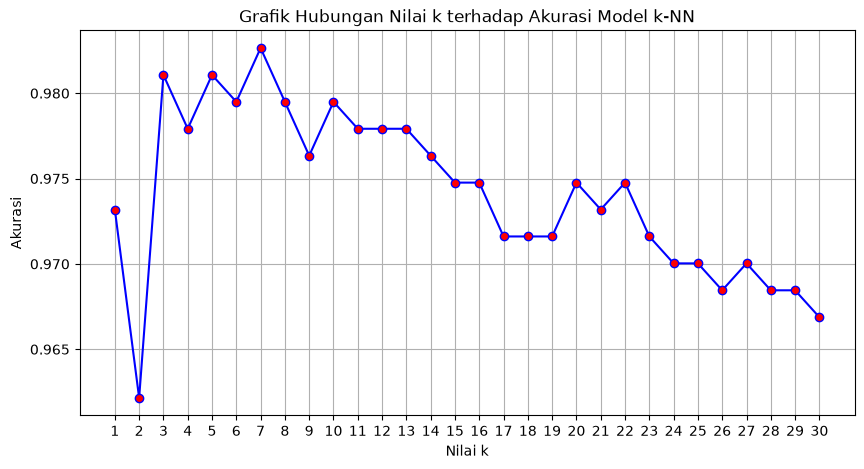

Nilai k terbaik adalah 7 dengan akurasi tertinggi sebesar 98.26%


In [10]:
# Mencoba nilai k dari 1 sampai 30
k_range = range(1, 31)
accuracy_scores = []

for k in k_range:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled, y_train)
    y_pred_temp = knn_temp.predict(X_test_scaled)
    accuracy_scores.append(accuracy_score(y_test, y_pred_temp))

# Visualisasi grafik akurasi vs nilai k
plt.figure(figsize=(10, 5))
plt.plot(k_range, accuracy_scores, marker='o', linestyle='-', color='b', mfc='red')
plt.title('Grafik Hubungan Nilai k terhadap Akurasi Model k-NN')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.grid(True)
plt.xticks(k_range)
plt.show()

# Menampilkan nilai k terbaik
best_k = k_range[np.argmax(accuracy_scores)]
print(f"Nilai k terbaik adalah {best_k} dengan akurasi tertinggi sebesar {max(accuracy_scores)*100:.2f}%")

=== 10 FITUR PALING OPTIMAL/PENTING ===
       Fitur  Importance
12   meanfun    0.339284
5        IQR    0.215487
3        Q25    0.149096
1         sd    0.075059
8     sp.ent    0.040202
9        sfm    0.023119
0   meanfreq    0.020999
11  centroid    0.020777
10      mode    0.015594
2     median    0.013001


C:\Users\ADVAn\AppData\Local\Temp\ipykernel_25476\2090257715.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Fitur', data=feature_imp.head(10), palette='viridis')


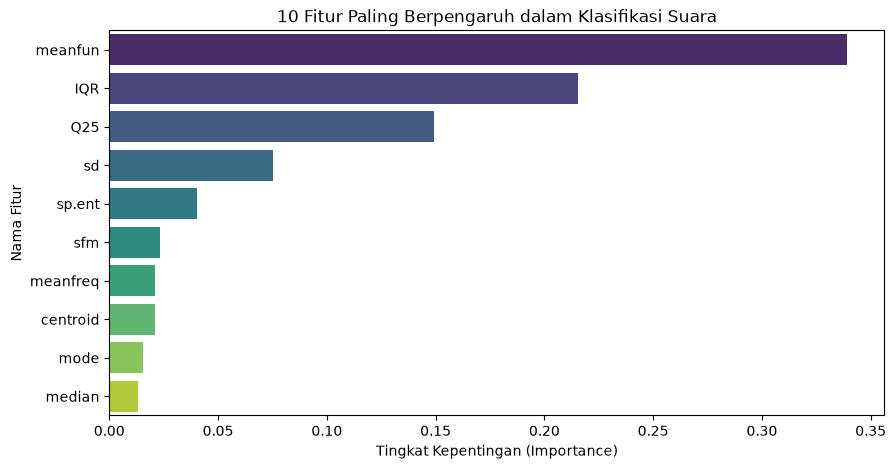

In [11]:
from sklearn.ensemble import RandomForestClassifier

# Melatih Random Forest untuk melihat fitur yang paling berpengaruh
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

# Membuat DataFrame tingkat kepentingan fitur
feature_imp = pd.DataFrame({'Fitur': X.columns, 'Importance': rf.feature_importances_})
feature_imp = feature_imp.sort_values(by='Importance', ascending=False)

print("=== 10 FITUR PALING OPTIMAL/PENTING ===")
print(feature_imp.head(10))

# Visualisasi 10 fitur teratas
plt.figure(figsize=(10, 5))
sns.barplot(x='Importance', y='Fitur', data=feature_imp.head(10), palette='viridis')
plt.title('10 Fitur Paling Berpengaruh dalam Klasifikasi Suara')
plt.xlabel('Tingkat Kepentingan (Importance)')
plt.ylabel('Nama Fitur')
plt.show()